# Figure 1 - Trajectories by IPO phase from 4.7 million km$^2$

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import scipy.stats as stats
import glob

In [2]:
model_names = [
    'ACCESS-ESM1-5', 'CESM2-LENS', 'CanESM5', 'EC-Earth3', 
    'MIROC6', 'MPI-ESM1-2-LR', 'CanESM2', 'CESM1'
]

model_years = {
    'CanESM5':[1850,2100], 'CESM2-LENS':[1850,2100], 'ACCESS-ESM1-5':[1850,2100], 
    'MPI-ESM1-2-LR':[1850,2100], 'MIROC6':[1850,2100], 'EC-Earth3':[1850,2100], 
    'CanESM2':[1950,2100], 'CESM1':[1920,2100],
}

## Load Sea Ice Extent (SIE) data

In [3]:
#load the September SIE
All_SIE = xr.open_dataset('/glade/work/cwpowell/ice-free/sea_ice_data/All_Model_September_SIE.nc')

sep_SIE = {}

for model_name in model_names:
    #drop NA members caused by models with different member names
    sep_SIE[model_name] = All_SIE[model_name].dropna(dim='member', how='all').dropna(dim='time', how='all')
    
#compute a rolling 11-year average
sep_SIE_11yr = {}

for model_name in model_names:
    sep_SIE_11yr[model_name] = sep_SIE[model_name].rolling(time=11, center=True).mean()

In [4]:
#calculate trajectory years starting from the closest year to the selected 
#SIE, cut off at 1960 to avoid 1942 being selected for
#CESM2-LENS member 1301.010 and 1950s/1960s dips for CanESM2

obs_11yr = 4.667 #2007-20217 mean NSIDC sea ice index v3

traj_start_yr = {}
for model_name in model_names:
    data = sep_SIE_11yr[model_name].sel(time=slice('1960','2100'))
    ranked_SIE = abs(data-obs_11yr).rank('time')
    ranked_SIE_years = ranked_SIE.where(ranked_SIE==1)
    traj_start_yr[model_name] = ranked_SIE['time'].where(
        ranked_SIE_years==1).max('time')

In [5]:
#compute the 50-year SIE trajectories from their start years
SIE_traj = {}

for model_name in model_names:
    
    model_SIE_traj = []
    for mem_ in np.sort(sep_SIE_11yr[model_name]['member']):

        data = sep_SIE_11yr[model_name].sel(member=mem_)
        start_yr = int(traj_start_yr[model_name].sel(member=mem_).values)
        
        traj_data = data.sel(time=slice(str(start_yr),str(start_yr+50)))
        traj_data['time'] = np.arange(0,51)              
        model_SIE_traj.append(traj_data)

    model_SIE_traj = xr.concat((model_SIE_traj),dim='member')
    model_SIE_traj['member'] = np.sort(sep_SIE_11yr[model_name]['member'])
    SIE_traj[model_name] = model_SIE_traj

## Load the IPO data

In [6]:
path = ('/glade/work/cwpowell/low-freq-trajectories/SST_for_IPO/'
        'IPO_per_Screen_Deser/IPO_11yr_annual_av_TPI_filtered_11yr_Lanczos_all_models.nc')

all_TPI = {model_name: xr.open_dataarray(path, group=model_name)
              for model_name in model_names}

#categorize members by -ve, neutral, +ve
threshold = 0.9 #sigma
IPO_sign = {}

for model_name in model_names:

    var_signs = []
    mem_list = np.sort(traj_start_yr[model_name]['member'])
    mem_used = []
    for mem_ in mem_list:
        
        try:
            start_yr = int(traj_start_yr[model_name].sel(member=mem_).values)

            var_value = all_TPI[model_name].sel(member=mem_).sel(
                year=start_yr).values

            if var_value < -threshold: 
                sign = -1
            elif var_value > threshold: 
                sign = 1
            else:
                sign = 0

            var_signs.append(sign)
            mem_used.append(mem_)
        
        except KeyError:
            print(model_name, mem_, 'SIE data but no IPO data')

    var_signs = xr.DataArray(
        data = var_signs,
        coords = {'member':mem_used},
        dims = ['member']
    )

    IPO_sign[model_name] = var_signs

EC-Earth3 r11i1p1f1 SIE data but no IPO data
EC-Earth3 r13i1p1f1 SIE data but no IPO data
EC-Earth3 r15i1p1f1 SIE data but no IPO data
EC-Earth3 r1i1p1f1 SIE data but no IPO data
EC-Earth3 r4i1p1f1 SIE data but no IPO data
EC-Earth3 r6i1p1f1 SIE data but no IPO data


## Plot Figure 1

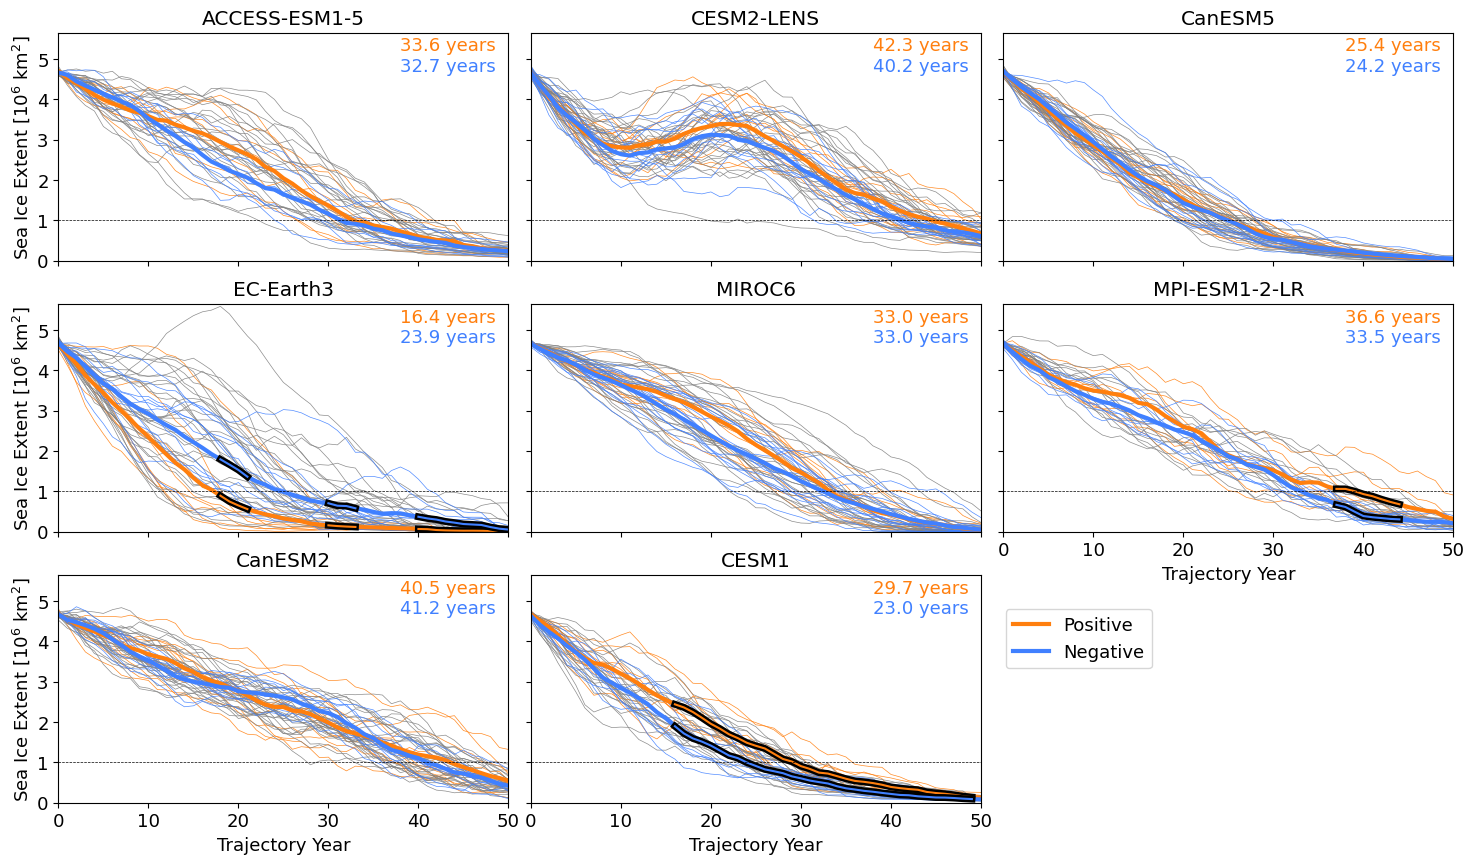

In [7]:
#plot all 11 GCMs' trajectories based on initial IPO phase
pos_col = 'tab:orange'#'tab:orange'
neg_col = [0.25,0.5,1]#'tab:cyan'

fig, axes = plt.subplots(3,3,figsize=[18,10])

for model_i, model_name in enumerate(model_names):
    
    ax_x = int(np.floor(model_i / 3))
    ax_y = int(model_i % 3)
    
    pos_mem = IPO_sign[model_name]['member'].where(
        IPO_sign[model_name]==1, drop=True)
    neu_mem = IPO_sign[model_name]['member'].where(
        IPO_sign[model_name]==0, drop=True)
    neg_mem = IPO_sign[model_name]['member'].where(
        IPO_sign[model_name]==-1, drop=True)

    #plot all trajectories by IPO phase
    for mem_ in pos_mem:
        axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
            member=mem_), color=pos_col, linewidth=0.5, alpha=0.9)
    for mem_ in neu_mem:
        axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
            member=mem_), color='0.5', linewidth=0.5, alpha=0.9)
    for mem_ in neg_mem:
        axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
            member=mem_), color=neg_col, linewidth=0.5, alpha=0.9)

    #plot the composite for each IPO phase
    axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
        member=pos_mem).mean('member'), c=pos_col, linewidth=3, label='Positive')
    axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
        member=neg_mem).mean('member'), c=neg_col, linewidth=3, label='Negative')
    
    #plot a black boarder if statistically significant from each other
    t_test = stats.ttest_ind(
        SIE_traj[model_name].sel(member=pos_mem),
        SIE_traj[model_name].sel(member=neg_mem), axis=0)    

    axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
        member=pos_mem).mean('member').where(t_test[1]<0.05), c=pos_col,
        path_effects=[pe.Stroke(linewidth=5, foreground='k'), pe.Normal()])
    
    axes[ax_x,ax_y].plot(np.arange(0,51), SIE_traj[model_name].sel(
        member=neg_mem).mean('member').where(t_test[1]<0.05), c=neg_col,
        path_effects=[pe.Stroke(linewidth=5, foreground='k'), pe.Normal()])
    
    #plot text for the first crossing of 1 million square km (Ice-Free)
    ranked_less1 = (SIE_traj[model_name]['time'].where(
        SIE_traj[model_name].sel(member=pos_mem)<1).rank('time'))
    IF_pos = SIE_traj[model_name]['time'].where(ranked_less1==1).max(
        'time').mean()
    ranked_less1 = (SIE_traj[model_name]['time'].where(
        SIE_traj[model_name].sel(member=neg_mem)<1).rank('time'))
    IF_neg = SIE_traj[model_name]['time'].where(ranked_less1==1).max(
        'time').mean()

    #add the composite time to ice-free conditions
    axes[ax_x,ax_y].text(38,5.2,str(np.round(float(IF_pos),1))+' years',
                         color=pos_col, fontsize=13)
    axes[ax_x,ax_y].text(38,4.7,str(np.round(float(IF_neg),1))+' years',
                         color=neg_col, fontsize=13)

    #add ice-free 1 million sq km dashed line
    axes[ax_x,ax_y].axhline(1, c='k', linewidth=0.5, linestyle='--')

    #set axes limits, ticks and titles
    axes[ax_x,ax_y].set_xlim(0,50)
    axes[ax_x,ax_y].set_ylim(0,5.65)
       
    axes[ax_x,ax_y].set_yticks([0,1,2,3,4,5])
    if model_i in [0,3,6]:
        axes[ax_x,ax_y].set_yticklabels(['0','1','2','3','4','5'], fontsize=13)
        axes[ax_x,ax_y].set_ylabel(r'Sea Ice Extent [10$^6$ km$^2$]',
                                   fontsize=13)
    else:
        axes[ax_x,ax_y].set_yticklabels([])
        
    if model_i in [5,6,7]:
        axes[ax_x,ax_y].set_xticks([0,10,20,30,40,50])
        axes[ax_x,ax_y].set_xticklabels(['0','10','20','30','40','50'], 
                                        fontsize=13)
        axes[ax_x,ax_y].set_xlabel('Trajectory Year', fontsize=13)
    else:
        axes[ax_x,ax_y].set_xticks([0,10,20,30,40,50])
        axes[ax_x,ax_y].set_xticklabels([])
    
    #add legend
    if model_i == 5:
        axes[ax_x,ax_y].legend(fontsize=13, bbox_to_anchor=(0.35, -0.3))
    #add title
    axes[ax_x,ax_y].set_title(model_name, fontsize=14.5)
    
fig.delaxes(axes[2,2])

plt.subplots_adjust(hspace=0.19, wspace=0.05)
# fig.savefig('/glade/work/cwpowell/ice-free/figures/Figure_1.pdf', bbox_inches='tight')